In [1]:


import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix


In [2]:

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


In [3]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Data is ready!")
print("Training shape:", X_train.shape)


Data is ready!
Training shape: torch.Size([120, 4])


In [4]:

class SoftDecisionTree(nn.Module):
    def __init__(self, input_size=4, num_classes=3):
        super().__init__()

        self.decision = nn.Linear(input_size, 1)
        self.leaves = nn.Parameter(torch.randn(2, num_classes) * 0.1)

    def forward(self, x):
        p = torch.sigmoid(self.decision(x))

        left = torch.softmax(self.leaves[0], dim=0)
        right = torch.softmax(self.leaves[1], dim=0)

        return (1 - p) * left + p * right


class DifferentiableRandomForest(nn.Module):
    def __init__(self, num_trees=10):
        super().__init__()

        self.trees = nn.ModuleList([
            SoftDecisionTree() for _ in range(num_trees)
        ])

    def forward(self, x):
        predictions = [tree(x) for tree in self.trees]
        return torch.stack(predictions).mean(dim=0)


torch.manual_seed(42)

model = DifferentiableRandomForest(num_trees=10)

print("Model created successfully!")


Model created successfully!


In [5]:

criterion = nn.NLLLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

losses = []

for epoch in range(1000):
    model.train()

    optimizer.zero_grad()

    outputs = model(X_train)

    loss = criterion(
        torch.log(outputs.clamp(min=1e-8)),
        y_train
    )

    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss.item():.4f}")


Epoch 100, Loss: 1.0657
Epoch 200, Loss: 1.0043
Epoch 300, Loss: 0.9296
Epoch 400, Loss: 0.8610
Epoch 500, Loss: 0.8028
Epoch 600, Loss: 0.7540
Epoch 700, Loss: 0.7133
Epoch 800, Loss: 0.6794
Epoch 900, Loss: 0.6514
Epoch 1000, Loss: 0.6281


In [6]:

model.eval()

with torch.no_grad():
    outputs = model(X_test)
    predictions = torch.argmax(outputs, dim=1)

accuracy = accuracy_score(y_test.numpy(), predictions.numpy())

print(f"Adam Accuracy: {accuracy * 100:.2f}%")


Adam Accuracy: 80.00%


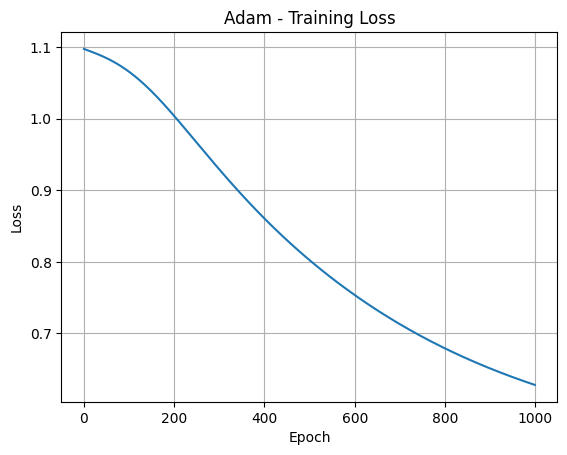

In [7]:

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Adam - Training Loss")
plt.grid(True)
plt.show()


In [8]:

cm = confusion_matrix(y_test.numpy(), predictions.numpy())

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[10  0  0]
 [ 0  4  6]
 [ 0  0 10]]
